In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer

In [3]:


df = pd.read_csv("titanic_data_updated.csv")


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,no,third,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,yes,first,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,yes,third,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,yes,first,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,no,third,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,no,second,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,yes,first,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,no,third,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,yes,first,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


Question 1 (10 Marks)
Load the Titanic dataset and display:
Dataset shape
First 10 rows
5 random samples


In [4]:
print(df.shape)
print(df.head(10))
print(df.sample(5))

(891, 12)
   PassengerId Survived  Pclass  \
0            1       no   third   
1            2      yes   first   
2            3      yes   third   
3            4      yes   first   
4            5       no   third   
5            6       no   third   
6            7       no   first   
7            8       no   third   
8            9      yes   third   
9           10      yes  second   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   
5                                   Moran, Mr. James    male   NaN      0   
6                            McCarthy, Mr. Timothy J    male  54.

Question 2 (10 Marks)
Perform feature screening on the Titanic dataset by:
Finding total missing values
Finding duplicate rows
Removing duplicate rows permanently


In [8]:
print(df.isnull().sum())
print(df.duplicated().sum())
df.drop_duplicates(inplace=True)
print(print(df.duplicated().sum()))

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64
0
0
None


Question 3 (10 Marks)
Perform statistical profiling of the Titanic dataset and display:
Dataset information
Statistical summary of numerical columns
Also write 2 observations from the output.


In [9]:
print(df.info())
print(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    object 
 2   Pclass       891 non-null    object 
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(3), object(7)
memory usage: 83.7+ KB
None
       PassengerId         Age       SibSp       Parch        Fare
count   891.000000  714.000000  891.000000  891.000000  891.000000
mean    446.000000   29.699118    0.523008    0.381594   32.204208
std     257.353842   14.526497    1.10

Observations:
1. The Age column has missing values because its count is lower than the total number of rows.
2. The average passenger age is around 29 years, and the maximum fare paid is much higher than the average fare, indicating some passengers paid significantly more.

Question 4 (10 Marks)
Perform univariate categorical analysis on the Survived column by:
Creating a countplot
Calculating percentage distribution
Creating a pie chart
Write 2 insights from the analysis.


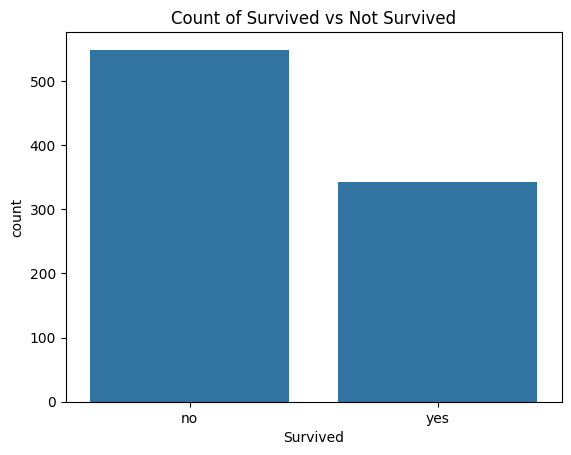

In [10]:
sns.countplot(data=df,x="Survived")
plt.title("Count of Survived vs Not Survived")
plt.show()

In [11]:
(df["Survived"].value_counts()/len(df))*100

Survived
no     61.616162
yes    38.383838
Name: count, dtype: float64

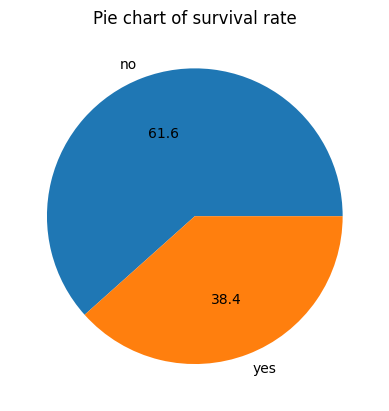

In [12]:
survived_count=df["Survived"].value_counts()
survived_label=df["Survived"].unique()

plt.pie(survived_count,labels=survived_label,autopct="%1.1f")
plt.title("Pie chart of survival rate")
plt.show()

2 Insights from the Analysis:
1. The number of passengers who did not survive is higher than those who survived, indicating a low overall survival rate.
2. The survival percentage shows that less than half of the passengers survived, meaning the disaster had a high fatality impact.

Question 5 (10 Marks)
Perform univariate numerical analysis on the Age column by:
Creating a histogram
Creating a KDE plot
Write 2 observations from the plots.


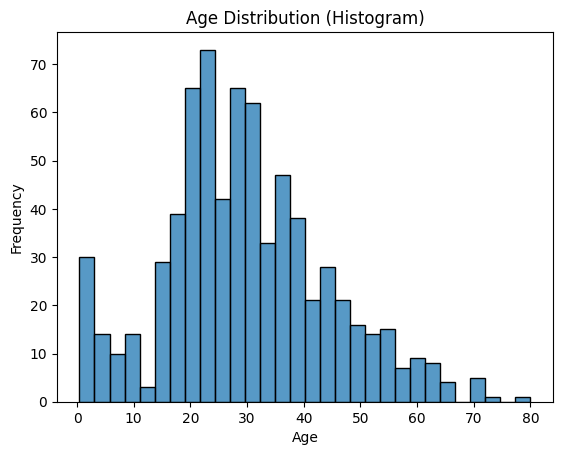

In [37]:
sns.histplot(df["Age"], bins=30)
plt.title("Age Distribution (Histogram)")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()

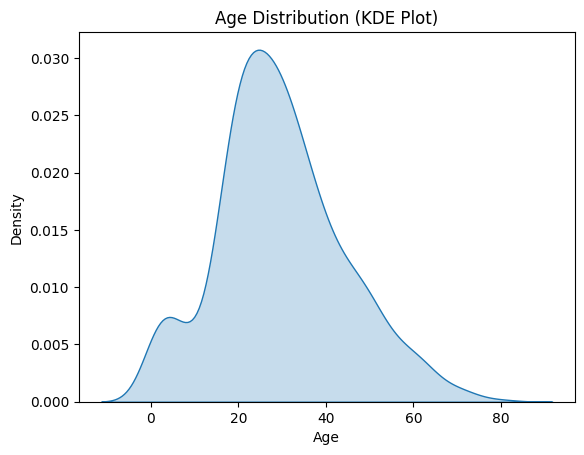

In [15]:
sns.kdeplot(df["Age"], fill=True)
plt.title("Age Distribution (KDE Plot)")
plt.xlabel("Age")
plt.ylabel("Density")
plt.show()

2 Observations:
1. The age distribution is slightly right-skewed, meaning there are more younger passengers compared to older ones.
2. Most passengers are concentrated in the age range of around 20 to 40 years, showing that adults made up the majority of the Titanic passengers.

Question 6 (10 Marks)
Perform multivariate analysis between Sex and Survived using a countplot with hue.
Also calculate normalized survival ratios using groupby().
Write 2 insights from the analysis.

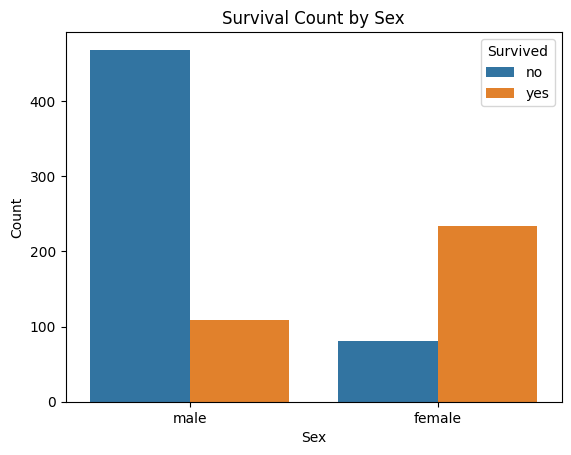

In [19]:
sns.countplot(data=df, x="Sex", hue="Survived")
plt.title("Survival Count by Sex")
plt.xlabel("Sex")
plt.ylabel("Count")
plt.show()


In [23]:
survival_ratio = df.groupby("Sex")["Survived"].value_counts(normalize=True)
survival_ratio

Sex     Survived
female  yes         0.742038
        no          0.257962
male    no          0.811092
        yes         0.188908
Name: proportion, dtype: float64

2 Insights:
1. Female passengers had a much higher survival rate compared to male passengers, showing a strong gender-based survival difference.
2. Male passengers had a significantly higher number of non-survivors, indicating they were less likely to survive during the disaster.

Question 7 (10 Marks)
Create a barplot showing the relationship between Pclass and Fare.
Write 2 observations from the visualization.


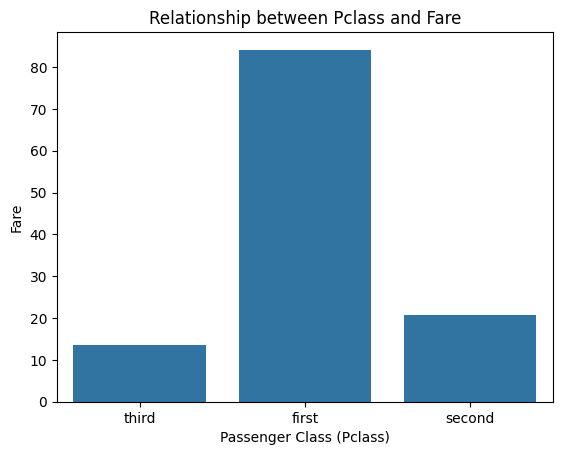

In [26]:
sns.barplot(data=df,x="Pclass", y="Fare",errorbar=None)
plt.title("Relationship between Pclass and Fare")
plt.xlabel("Passenger Class (Pclass)")
plt.ylabel("Fare")
plt.show()

2 Observations:
1. First class passengers (Pclass 1) generally paid the highest fares compared to second and third class passengers.
2. Third class passengers (Pclass 3) had the lowest average fare, showing a clear difference in ticket pricing across classes.

Question 8 (10 Marks)
Create a KDE plot to compare the Age distribution of survived and non-survived passengers.
Write 2 insights from the graph.


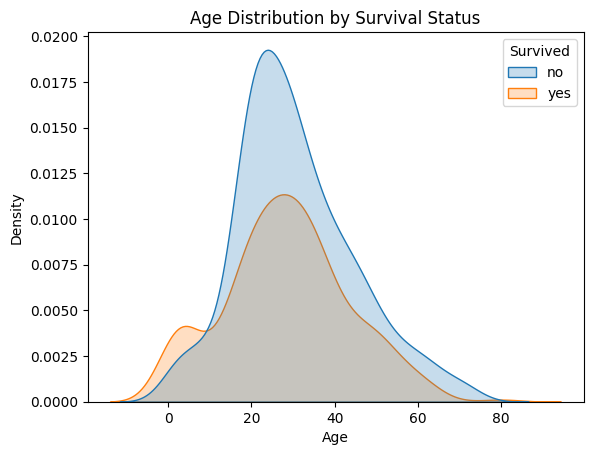

In [27]:
sns.kdeplot(data=df, x="Age", hue="Survived", fill=True)

plt.title("Age Distribution by Survival Status")
plt.xlabel("Age")
plt.ylabel("Density")
plt.show()

2 Insights:
1. Survivors are more concentrated in younger age groups, especially children and young adults.
2. Non-survivors show a broader spread across adult ages, indicating higher mortality among middle-aged passengers.

Question 9 (10 Marks)
Perform feature engineering and train-test split by:
Dropping PassengerId, Name, and Ticket columns
Separating features (X) and target (y)
Splitting the dataset using test_size=0.2 and random_state=42
Display the shapes of train and test datasets.


In [28]:
df = df.drop(columns=["PassengerId", "Name", "Ticket"])
X = df.drop("Survived", axis=1)
y = df["Survived"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(712, 8)
(179, 8)
(712,)
(179,)


Question 10 (10 Marks)
Handle missing values in the Titanic dataset by:
Imputing missing Age values using SimpleImputer with mean strategy
Imputing missing Embarked values using most frequent strategy
Imputing missing Cabin values using constant strategy with "Missing"
Finally, check whether any missing values remain.


In [34]:
from sklearn.impute import SimpleImputer

age_imputer = SimpleImputer(missing_values=np.nan , strategy='mean')

age_imputer.fit(X_train[['Age']]) 

X_train['Age'] = age_imputer.transform(X_train[['Age']]).ravel()
X_test['Age'] = age_imputer.transform(X_test[['Age']]).ravel()

In [30]:
embarked_imputer = SimpleImputer(missing_values=np.nan , strategy='most_frequent')

embarked_imputer.fit(X_train[['Embarked']]) 

X_train['Embarked']= embarked_imputer.transform(X_train[['Embarked']]).ravel() 


In [31]:
cabin_imputer = SimpleImputer(missing_values=np.nan , strategy='constant',fill_value='Missing',add_indicator=True)

cabin_imputer.fit(X_train[['Cabin']])

X_train[['Cabin','cabin_missing_indicator']]= cabin_imputer.transform(X_train[['Cabin']])
X_test[['Cabin','cabin_missing_indicator']] = cabin_imputer.transform(X_test[['Cabin']])


In [36]:
print(X_train.isnull().sum())

Pclass                     0
Sex                        0
Age                        0
SibSp                      0
Parch                      0
Fare                       0
Cabin                      0
Embarked                   0
cabin_missing_indicator    0
dtype: int64


In [35]:
print(X_test.isnull().sum())

Pclass                     0
Sex                        0
Age                        0
SibSp                      0
Parch                      0
Fare                       0
Cabin                      0
Embarked                   0
cabin_missing_indicator    0
dtype: int64
